In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Основні датасети
transfers = pd.read_csv('data/data_raw/transfers.csv')
appearances = pd.read_csv('data/data_raw/appearances.csv')
players = pd.read_csv('data/data_raw/players.csv')
clubs = pd.read_csv('data/data_raw/clubs.csv')
competitions = pd.read_csv('data/data_raw/competitions.csv')

In [5]:
#Опціональні для Feature Engineering
player_valuations = pd.read_csv('data/data_raw/player_valuations.csv')
national_teams = pd.read_csv('data/data_raw/national_teams.csv')
countries = pd.read_csv('data/data_raw/countries.csv')

In [6]:
def get_data_info(df):
    print(f"Shape: {df.shape}")
    print(f"Info: {df.info()}")
    print(f"Missing values:\n{df.isnull().sum()}")

In [7]:
#oбираємо потрібін атрибути 

transfers = transfers[[
    'player_id',
    'transfer_date',
    'transfer_season',
    'from_club_id',
    'to_club_id',
    'transfer_fee',
    'market_value_in_eur'
]]

players = players[[
    'player_id',
    'country_of_citizenship',
    'date_of_birth',
    'position',
    'sub_position',
    'foot',
    'height_in_cm'
]]

appearances = appearances[[
    'player_id',
    'player_club_id',
    'date',
    'competition_id',
    'yellow_cards',
    'red_cards',
    'goals',
    'assists',
    'minutes_played'
]]

clubs = clubs[[
    'club_id',
    'domestic_competition_id',
    'squad_size',
    'average_age',
    'foreigners_percentage',
    'national_team_players',
    'stadium_seats',
    'net_transfer_record'
]]

competitions = competitions[[
    'competition_id',
    'name',
    'sub_type',
    'type',
    'country_name',
    'confederation',
    'total_clubs'
]]


In [8]:
transfers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175165 entries, 0 to 175164
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   player_id            175165 non-null  int64  
 1   transfer_date        175165 non-null  object 
 2   transfer_season      175165 non-null  object 
 3   from_club_id         175165 non-null  int64  
 4   to_club_id           175165 non-null  int64  
 5   transfer_fee         113639 non-null  float64
 6   market_value_in_eur  107005 non-null  float64
dtypes: float64(2), int64(3), object(2)
memory usage: 9.4+ MB


In [9]:
transfers.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,transfer_fee,market_value_in_eur
0,467994,2030-06-30,25/26,5621,749,0.0,700000.0
1,645842,2028-02-02,27/28,6505,19684,0.0,150000.0
2,677470,2028-02-02,27/28,6505,3535,0.0,400000.0
3,709155,2028-02-02,27/28,6505,19684,0.0,325000.0
4,728133,2028-02-02,27/28,6505,35759,0.0,175000.0


In [10]:
transfers.isna().sum()

player_id                  0
transfer_date              0
transfer_season            0
from_club_id               0
to_club_id                 0
transfer_fee           61526
market_value_in_eur    68160
dtype: int64

In [11]:
transfers.value_counts()

player_id  transfer_date  transfer_season  from_club_id  to_club_id  transfer_fee  market_value_in_eur
2989       2006-07-01     06/07            27            41          2500000.0     3000000.0              1
517704     2018-01-31     17/18            10789         3323        0.0           25000.0                1
517705     2024-01-30     23/24            3345          2503        0.0           125000.0               1
           2023-08-08     23/24            2503          3345        0.0           150000.0               1
           2023-06-30     22/23            1701          2503        0.0           150000.0               1
                                                                                                         ..
271282     2019-08-27     19/20            16704         40812       1500000.0     1000000.0              1
           2019-06-30     18/19            170           16704       0.0           1000000.0              1
           2018-07-01     18/19  

In [12]:
# 1. Переводимо дату з тексту (object) у формат дати (datetime)
transfers['transfer_date'] = pd.to_datetime(transfers['transfer_date'])

# 2. Видаляємо повні дублікати, якщо вони є
transfers = transfers.drop_duplicates()

# 3. (прибираємо NaN та 0.0 — це оренди і вільні агенти)
transfers = transfers[transfers['transfer_fee'] > 0]

# 4. Прибираємо майбутні дати (датасет актуальний до 6 липня 2026 року)
transfers = transfers[transfers['transfer_date'] <= '2026-07-06']

# 5. Прибираємо аномалії, де клуб-продавець і клуб-покупець однакові
transfers = transfers[transfers['from_club_id'] != transfers['to_club_id']]

# 6. Оновлюємо індекси після фільтрації
transfers = transfers.reset_index(drop=True)

In [13]:
print("Новий розмір:", transfers.shape)
print("\nПропуски після очищення:")
print(transfers.isna().sum())
print("\nДіапазон дат:", transfers['transfer_date'].min(), "—", transfers['transfer_date'].max())

Новий розмір: (17547, 7)

Пропуски після очищення:
player_id                 0
transfer_date             0
transfer_season           0
from_club_id              0
to_club_id                0
transfer_fee              0
market_value_in_eur    1112
dtype: int64

Діапазон дат: 1997-07-01 00:00:00 — 2026-07-02 00:00:00


In [14]:
get_data_info(players)

Shape: (50149, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50149 entries, 0 to 50148
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   player_id               50149 non-null  int64  
 1   country_of_citizenship  49880 non-null  object 
 2   date_of_birth           50100 non-null  object 
 3   position                50149 non-null  object 
 4   sub_position            49563 non-null  object 
 5   foot                    44256 non-null  object 
 6   height_in_cm            45784 non-null  float64
dtypes: float64(1), int64(1), object(5)
memory usage: 2.7+ MB
Info: None
Missing values:
player_id                    0
country_of_citizenship     269
date_of_birth               49
position                     0
sub_position               586
foot                      5893
height_in_cm              4365
dtype: int64


In [15]:
players.head()

,player_id,country_of_citizenship,date_of_birth,position,sub_position,foot,height_in_cm
0,10,Germany,1978-06-09 00:00:00,Attack,Centre-Forward,right,184.0
1,26,Germany,1980-08-06 00:00:00,Goalkeeper,Goalkeeper,left,190.0
2,65,Bulgaria,1981-01-30 00:00:00,Attack,Centre-Forward,NaN,NaN
3,77,Brazil,1978-05-08 00:00:00,Defender,Centre-Back,NaN,NaN
4,80,Germany,1981-03-18 00:00:00,Goalkeeper,Goalkeeper,right,194.0


In [16]:
# 1. Переводимо дату народження у формат datetime
players['date_of_birth'] = pd.to_datetime(players['date_of_birth'])

# 2. Видаляємо можливі дублікати за player_id
players = players.drop_duplicates(subset=['player_id'])

# 3. Залишаємо лише гравців, які є в нашій очищеній таблиці transfers
players = players[players['player_id'].isin(transfers['player_id'])]

# 4. Видаляємо рядки без дати народження (без неї не порахувати вік гравця)
players = players.dropna(subset=['date_of_birth'])

# 5. Замінюємо пропуски в текстових колонках на 'Unknown'
players['country_of_citizenship'] = players['country_of_citizenship'].fillna('Unknown')
players['sub_position'] = players['sub_position'].fillna('Unknown')
players['foot'] = players['foot'].fillna('Unknown')

# 6. Перевіряємо зріст на аномалії (якщо < 140 см або > 220 см — ставимо NaN)
players.loc[(players['height_in_cm'] < 140) | (players['height_in_cm'] > 220), 'height_in_cm'] = np.nan

# 7. Оновлюємо індекси
players = players.reset_index(drop=True)




In [17]:
# 8. Перевіряємо результат
print("Новий розмір:", players.shape)
print("\nПропуски після очищення:")
print(players.isna().sum())
print("\nУнікальні позиції:")
print(players['position'].value_counts())

Новий розмір: (9949, 7)

Пропуски після очищення:
player_id                  0
country_of_citizenship     0
date_of_birth              0
position                   0
sub_position               0
foot                       0
height_in_cm              64
dtype: int64

Унікальні позиції:
position
Attack        3179
Defender      3162
Midfield      2833
Goalkeeper     774
Missing          1
Name: count, dtype: int64


In [18]:
print("\nУнікальні значення foot:")
print(players['foot'].value_counts())
print("\nСтатистика зросту:")
print(players['height_in_cm'].describe())


Унікальні значення foot:
foot
right      6911
left       2533
both        306
Unknown     199
Name: count, dtype: int64

Статистика зросту:
count    9885.000000
mean      182.494082
std         6.980641
min       158.000000
25%       178.000000
50%       183.000000
75%       188.000000
max       206.000000
Name: height_in_cm, dtype: float64


In [19]:
#Видаляєм одного футболіста, у якого позиція Missing
players = players[players['position'] != 'Missing'].reset_index(drop=True)

In [20]:
get_data_info(appearances)

Shape: (1894350, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1894350 entries, 0 to 1894349
Data columns (total 9 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   player_id       int64 
 1   player_club_id  int64 
 2   date            object
 3   competition_id  object
 4   yellow_cards    int64 
 5   red_cards       int64 
 6   goals           int64 
 7   assists         int64 
 8   minutes_played  int64 
dtypes: int64(7), object(2)
memory usage: 130.1+ MB
Info: None
Missing values:
player_id         0
player_club_id    0
date              0
competition_id    0
yellow_cards      0
red_cards         0
goals             0
assists           0
minutes_played    0
dtype: int64


In [21]:
appearances.head()

,player_id,player_club_id,date,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,38004,853,2012-07-03,CLQ,0,0,2,0,90
1,79232,8841,2012-07-05,ELQ,0,0,0,0,90
2,42792,6251,2012-07-05,ELQ,0,0,0,0,45
3,73333,1274,2012-07-05,ELQ,0,0,0,0,90
4,122011,195,2012-07-05,ELQ,0,0,0,1,90


In [22]:
# 1. Переводимо дату у формат datetime
appearances['date'] = pd.to_datetime(appearances['date'])

# 2. Залишаємо статистику лише для гравців, які є в нашій очищеній таблиці players
appearances = appearances[appearances['player_id'].isin(players['player_id'])]

# 3. Видаляємо можливі повні дублікати
appearances = appearances.drop_duplicates()

# 4. Прибираємо можливі аномалії (матчі з 0 хвилин або від'ємні значення)
appearances = appearances[
    (appearances['minutes_played'] > 0) &
    (appearances['goals'] >= 0) &
    (appearances['assists'] >= 0) &
    (appearances['yellow_cards'] >= 0) &
    (appearances['red_cards'] >= 0)
]

# 5. Оновлюємо індекси
appearances = appearances.reset_index(drop=True)

In [23]:
# 6. Перевіряємо результат
print("Новий розмір:", appearances.shape)
print("\nДіапазон дат:", appearances['date'].min(), "—", appearances['date'].max())
print("\nСтатистика числових колонок:")
print(appearances[['yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played']].describe())

Новий розмір: (912653, 9)

Діапазон дат: 2012-07-05 00:00:00 — 2026-06-28 00:00:00

Статистика числових колонок:
        yellow_cards      red_cards          goals        assists  \
count  912653.000000  912653.000000  912653.000000  912653.000000   
mean        0.137563       0.003073       0.110971       0.084603   
std         0.353009       0.055354       0.356002       0.302151   
min         0.000000       0.000000       0.000000       0.000000   
25%         0.000000       0.000000       0.000000       0.000000   
50%         0.000000       0.000000       0.000000       0.000000   
75%         0.000000       0.000000       0.000000       0.000000   
max         2.000000       1.000000       6.000000       5.000000   

       minutes_played  
count   912653.000000  
mean        68.555736  
std         29.905315  
min          1.000000  
25%         45.000000  
50%         90.000000  
75%         90.000000  
max        148.000000  


In [24]:
get_data_info(clubs)

Shape: (796, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 796 entries, 0 to 795
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   club_id                  796 non-null    int64  
 1   domestic_competition_id  796 non-null    object 
 2   squad_size               796 non-null    int64  
 3   average_age              758 non-null    float64
 4   foreigners_percentage    736 non-null    float64
 5   national_team_players    796 non-null    int64  
 6   stadium_seats            796 non-null    int64  
 7   net_transfer_record      796 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 49.9+ KB
Info: None
Missing values:
club_id                     0
domestic_competition_id     0
squad_size                  0
average_age                38
foreigners_percentage      60
national_team_players       0
stadium_seats               0
net_transfer_record         0
dtype: int

In [25]:
clubs.head()

,club_id,domestic_competition_id,squad_size,average_age,foreigners_percentage,national_team_players,stadium_seats,net_transfer_record
0,10,L1,27,25.3,55.6,4,26515,+€5.90m
1,10004,FR1,27,27.2,51.9,7,19904,€-25.00m
2,10010,BRA1,32,26.6,28.1,3,47364,+€8.14m
3,1003,GB1,29,25.9,58.6,9,32259,+€57.30m
4,1005,IT1,39,23.8,92.3,10,31559,+€3.35m


In [26]:
# 1. Видаляємо можливі дублікати за club_id
clubs = clubs.drop_duplicates(subset=['club_id'])

# 2. Залишаємо лише клуби, які фігурують у нашій таблиці transfers (як продавець або покупець)
clubs = clubs[
    clubs['club_id'].isin(transfers['from_club_id']) |
    clubs['club_id'].isin(transfers['to_club_id'])
]

# 3. Проста функція для переведення net_transfer_record з тексту в число (в євро)
def parse_money(val):
    val = str(val).strip()
    if val in ['+-0', '0', '']:
        return 0.0
    
    # Прибираємо знаки '€' та '+' (знак '-' залишиться)
    val = val.replace('€', '').replace('+', '')
    
    if val.endswith('m'):
        return float(val[:-1]) * 1_000_000
    elif val.endswith('k'):
        return float(val[:-1]) * 1_000
    else:
        try:
            return float(val)
        except ValueError:
            return np.nan

clubs['net_transfer_record'] = clubs['net_transfer_record'].apply(parse_money)

# 4. Замінюємо 0 на NaN у колонках, де нуль означає відсутність даних
clubs.loc[clubs['squad_size'] == 0, 'squad_size'] = np.nan
clubs.loc[clubs['stadium_seats'] == 0, 'stadium_seats'] = np.nan

# 5. Оновлюємо індекси
clubs = clubs.reset_index(drop=True)

In [27]:
# 6. Перевіряємо результат
print("Новий розмір:", clubs.shape)
print("\nПропуски після очищення:")
print(clubs.isna().sum())
print("\nСтатистика числових колонок:")
print(clubs.describe())

Новий розмір: (764, 8)

Пропуски після очищення:
club_id                     0
domestic_competition_id     0
squad_size                 32
average_age                29
foreigners_percentage      45
national_team_players       0
stadium_seats               1
net_transfer_record         0
dtype: int64

Статистика числових колонок:
             club_id  squad_size  average_age  foreigners_percentage  \
count     764.000000  732.000000   735.000000             719.000000   
mean     8389.155759   28.355191    25.481497              40.420584   
std     16168.901652    5.391594     2.272136              20.090537   
min         3.000000    3.000000     0.000000               2.400000   
25%       592.000000   26.000000    24.500000              24.250000   
50%      2141.000000   28.000000    25.600000              40.000000   
75%      6997.000000   31.000000    26.700000              55.200000   
max    114977.000000   50.000000    30.100000             100.000000   

       national_tea

In [28]:
clubs.loc[clubs['average_age'] == 0, 'average_age'] = np.nan

In [29]:
clubs.head()

,club_id,domestic_competition_id,squad_size,average_age,foreigners_percentage,national_team_players,stadium_seats,net_transfer_record
0,10,L1,27.0,25.3,55.6,4,26515.0,5900000.0
1,10004,FR1,27.0,27.2,51.9,7,19904.0,-25000000.0
2,10010,BRA1,32.0,26.6,28.1,3,47364.0,8140000.0
3,1003,GB1,29.0,25.9,58.6,9,32259.0,57300000.0
4,1005,IT1,39.0,23.8,92.3,10,31559.0,3350000.0


In [30]:
get_data_info(competitions)

Shape: (65, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   competition_id  65 non-null     object 
 1   name            65 non-null     object 
 2   sub_type        65 non-null     object 
 3   type            65 non-null     object 
 4   country_name    53 non-null     object 
 5   confederation   65 non-null     object 
 6   total_clubs     50 non-null     float64
dtypes: float64(1), object(6)
memory usage: 3.7+ KB
Info: None
Missing values:
competition_id     0
name               0
sub_type           0
type               0
country_name      12
confederation      0
total_clubs       15
dtype: int64


In [31]:
competitions.head()

,competition_id,name,sub_type,type,country_name,confederation,total_clubs
0,A1,bundesliga,first_tier,domestic_league,Austria,europa,12.0
1,AFAC,afc-asian-cup,afc_asian_cup,national_team_competition,NaN,asien,NaN
2,AFCN,africa-cup-of-nations,africa_cup_of_nations,national_team_competition,NaN,afrika,NaN
3,ARG1,torneo-apertura,first_tier,domestic_league,Argentina,amerika,30.0
4,AUS1,a-league-men,first_tier,domestic_league,Australia,asien,12.0


In [32]:
# 1. Видаляємо можливі дублікати за competition_id
competitions = competitions.drop_duplicates(subset=['competition_id'])

# 2. Заповнюємо пропуски в country_name значенням 'International'
competitions['country_name'] = competitions['country_name'].fillna('International')

# 3. Оновлюємо індекси
competitions = competitions.reset_index(drop=True)

# 4. Перевіряємо результат
print("Розмір:", competitions.shape)
print("\nПропуски:")
print(competitions.isna().sum())
print("\nТипи турнірів:")
print(competitions['type'].value_counts())


Розмір: (65, 7)

Пропуски:
competition_id     0
name               0
sub_type           0
type               0
country_name       0
confederation      0
total_clubs       15
dtype: int64

Типи турнірів:
type
domestic_league              31
other                        16
domestic_cup                 10
national_team_competition     5
international_cup             3
Name: count, dtype: int64


In [33]:
# 1. Залишаємо трансфери з 2013-07-01 та лише для гравців, які є в очищеному players
transfers = transfers[
    (transfers['transfer_date'] >= '2013-07-01') &
    (transfers['player_id'].isin(players['player_id']))
].reset_index(drop=True)

# 2. Синхронізуємо players, appearances та clubs під фінальний transfers
players = players[players['player_id'].isin(transfers['player_id'])].reset_index(drop=True)
appearances = appearances[appearances['player_id'].isin(transfers['player_id'])].reset_index(drop=True)
clubs = clubs[
    clubs['club_id'].isin(transfers['from_club_id']) |
    clubs['club_id'].isin(transfers['to_club_id'])
].reset_index(drop=True)

# 3. Перевіряємо фінальні розміри та пропуски в transfers
print("transfers:", transfers.shape)
print("players:", players.shape)
print("appearances:", appearances.shape)
print("clubs:", clubs.shape)
print("competitions:", competitions.shape)
print("\nПропуски в transfers.market_value_in_eur:", transfers['market_value_in_eur'].isna().sum())




transfers: (16624, 7)
players: (9779, 7)
appearances: (883515, 9)
clubs: (755, 8)
competitions: (65, 7)

Пропуски в transfers.market_value_in_eur: 886


In [34]:
#Пропуски в transfers.market_value_in_eur: 886
#Для моделі з оцінкою їх можна буде або просто дропнути перед навчанням, або за бажанням дозаповнити пізніше з таблиці player_valuations.csv

In [35]:
# 4. Зберігаємо очищені таблиці
transfers.to_csv('data/data_cleaned/clean_transfers.csv', index=False)
players.to_csv('data/data_cleaned/clean_players.csv', index=False)
appearances.to_csv('data/data_cleaned/clean_appearances.csv', index=False)
clubs.to_csv('data/data_cleaned/clean_clubs.csv', index=False)
competitions.to_csv('data/data_cleaned/clean_competitions.csv', index=False)

In [ ]:
# нормальне завантаженняя
transfers_ = pd.read_csv('data/data_cleaned/clean_transfers.csv')
transfers_c = transfers_.dropna(subset=['market_value_in_eur'])

players_c = pd.read_csv('data/data_cleaned/clean_players.csv')
appearances_c = pd.read_csv('data/data_cleaned/clean_appearances.csv')
clubs_c = pd.read_csv('data/data_cleaned/clean_clubs.csv')
competitions_c = pd.read_csv('data/data_cleaned/clean_competitions.csv')


In [ ]:
# merging of all data, competition was not used due to its making data sentetic as it dublicates the data(it will work only for pivot but pivots cant be used for ML)
transfers_players = pd.merge(transfers_c, players_c, on='player_id')
transfers_players['transfer_date'] = pd.to_datetime(transfers_players['transfer_date'])
appearances_c['date'] = pd.to_datetime(appearances_c['date'])

# 2. З'єднуємо і залишаємо лише матчі за 365 днів до трансферу
df = pd.merge(transfers_players, appearances_c, on='player_id')
df = df[(df['date'] < df['transfer_date']) & (df['date'] >= df['transfer_date'] - pd.Timedelta(days=365))]

# 3. appearances were used for statistic, per 1 year, as the transfer is done based in players statistic for one year(mostly) not for 1 game
stats = df.groupby(['player_id', 'transfer_date'], as_index=False).agg(
    appearances_365=('date', 'count'),
    goals_365=('goals', 'sum'),
    assists_365=('assists', 'sum'),
    yellow_cards_365=('yellow_cards', 'sum'),
    red_cards_365=('red_cards', 'sum'),
    minutes_played_365=('minutes_played', 'sum')
)

# 4. Додаємо до головної таблиці і замінюємо пустоти на 0
df2 = pd.merge(transfers_players, stats, on=['player_id', 'transfer_date'], how='left')

# adding from_clubs info
df3 = pd.merge(
    df2, 
    clubs_c[['club_id', 'average_age', 'squad_size', 'domestic_competition_id', 'foreigners_percentage']].rename(
        columns={
            'average_age': 'from_average_age',
            'squad_size': 'from_squad_size',
            'domestic_competition_id': 'from_club_league',
            'foreigners_percentage': 'from_club_foreigners_percentage'
        }
    ),
    left_on='from_club_id', 
    right_on='club_id', 
    how='left'
).drop(columns=['club_id'])
# adding to_clubs info
df4 = pd.merge(
    df3, 
    clubs_c[['club_id', 'average_age', 'squad_size', 'domestic_competition_id', 'foreigners_percentage']].rename(
        columns={
            'average_age': 'to_average_age',
            'squad_size': 'to_squad_size',
            'domestic_competition_id': 'to_club_league',
            'foreigners_percentage': 'to_club_foreigners_percentage'
        }
    ),
    left_on='to_club_id', 
    right_on='club_id', 
    how='left'
).drop(columns=['club_id'])
final = df4.dropna()

In [43]:
#feature engineering
df = final.copy()

# 1. Вік на момент трансферу (age_at_transfer)
df['transfer_date'] = pd.to_datetime(df['transfer_date'])
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])
df['age_at_transfer'] = (df['transfer_date'] - df['date_of_birth']).dt.days / 365.25

# 2. Ігрова ефективність за останній рік
# Використовуємо np.where для безпечного ділення (якщо хвилин або матчів 0 — ставимо 0)
df['goals_per_90'] = np.where(
    df['minutes_played_365'] > 0, 
    (df['goals_365'] / df['minutes_played_365']) * 90, 
    0
)

df['assists_per_90'] = np.where(
    df['minutes_played_365'] > 0, 
    (df['assists_365'] / df['minutes_played_365']) * 90, 
    0
)

df['goal_contributions_365'] = df['goals_365'] + df['assists_365']

df['minutes_per_appearance'] = np.where(
    df['appearances_365'] > 0, 
    df['minutes_played_365'] / df['appearances_365'], 
    0
)

# 3. Контекст ліг (Топ-5 ліг Європи у базі Transfermarkt)
# GB1 - АПЛ, ES1 - Ла Ліга, IT1 - Серія А, L1 - Бундесліга, FR1 - Ліга 1
top5_leagues = ['GB1', 'ES1', 'IT1', 'L1', 'FR1']

df['is_top5_to'] = df['to_club_league'].isin(top5_leagues).astype(int)
df['is_top5_from'] = df['from_club_league'].isin(top5_leagues).astype(int)

# Підвищення в класі: гравець перейшов НЕ з топ-5 ліги У топ-5 лігу
df['league_upgrade'] = ((df['is_top5_from'] == 0) & (df['is_top5_to'] == 1)).astype(int)
df


,player_id,transfer_date,transfer_season,from_club_id,to_club_id,transfer_fee,market_value_in_eur,country_of_citizenship,date_of_birth,position,...,to_club_league,to_club_foreigners_percentage,age_at_transfer,goals_per_90,assists_per_90,goal_contributions_365,minutes_per_appearance,is_top5_to,is_top5_from,league_upgrade
2,188888,2026-07-01,26/27,331,39,500000.0,1500000.0,Suriname,1995-02-09,Attack,...,L1,53.3,31.389459,0.273973,0.342466,9.0,52.560000,1,1,0
3,237658,2026-07-01,26/27,1025,4172,4500000.0,4000000.0,Switzerland,1997-01-06,Midfield,...,IT1,57.1,29.481177,0.028708,0.057416,3.0,80.384615,1,1,0
4,256361,2026-07-01,26/27,3522,6646,250000.0,700000.0,Italy,1996-06-20,Attack,...,TR1,33.3,30.028747,0.182927,0.731707,5.0,61.500000,0,1,0
5,257474,2026-07-01,26/27,416,6195,6000000.0,20000000.0,Serbia,1997-02-20,Goalkeeper,...,IT1,56.1,29.357974,0.000000,0.026316,1.0,90.000000,1,1,0
7,282388,2026-07-01,26/27,6195,416,7200000.0,7000000.0,Argentina,1995-07-05,Attack,...,IT1,63.0,30.989733,0.417369,0.075885,13.0,67.771429,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15710,160506,2013-07-01,13/14,447,6195,1000000.0,2500000.0,Croatia,1994-04-03,Midfield,...,IT1,56.1,19.244353,0.000000,0.000000,0.0,90.000000,1,0,1
15722,187105,2013-07-01,13/14,200,610,3800000.0,3000000.0,Netherlands,1992-10-15,Defender,...,NL1,57.7,20.709103,0.128434,0.064217,6.0,87.593750,0,0,0
15723,188335,2013-07-01,13/14,416,430,2500000.0,2000000.0,Montenegro,1993-11-01,Midfield,...,IT1,44.4,19.663244,0.000000,0.000000,0.0,69.000000,1,1,0
15728,203412,2013-07-01,13/14,190,603,8700000.0,4500000.0,Denmark,1993-03-16,Attack,...,GB1,85.7,20.292950,0.527086,0.131772,25.0,77.613636,1,0,1


In [ ]:
# choosing best features for trees
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# 1. Залишаємо платні трансфери та переводимо дати в числа (роки)
df_clean = df[df['transfer_fee'] > 0].copy()
df_clean['transfer_year'] = pd.to_datetime(df_clean['transfer_date']).dt.year
df_clean['birth_year'] = pd.to_datetime(df_clean['date_of_birth']).dt.year

# 3. Видаляємо лише сирі колонки, які ми вже замінили на правильні фічі
drop_cols = [
    'transfer_fee', 'player_id', 'from_club_id', 'to_club_id', 
    'transfer_date', 'date_of_birth', 'transfer_season', 'prev_year'
]

X = pd.get_dummies(df_clean.drop(columns=drop_cols, errors='ignore'), drop_first=True)
y = df_clean['transfer_fee']

# 4. Відбираємо топ-15 найважливіших фічів
rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1).fit(X, y)
top_features = pd.Series(rf.feature_importances_, index=X.columns).nlargest(15)

print(top_features)


market_value_in_eur                0.776507
age_at_transfer                    0.025317
to_club_league_GB1                 0.015516
from_club_foreigners_percentage    0.012986
assists_365                        0.009758
minutes_per_appearance             0.009577
to_average_age                     0.009292
assists_per_90                     0.009207
transfer_year                      0.008772
to_club_foreigners_percentage      0.008681
height_in_cm                       0.008386
minutes_played_365                 0.007949
goals_per_90                       0.007416
appearances_365                    0.007364
from_average_age                   0.007321
dtype: float64


Best parameters: {'n_estimators': 275, 'learning_rate': 0.033121250916432594, 'max_depth': 3, 'subsample': 0.6262189764339259, 'colsample_bytree': 0.9943380602542631}
             Модель      MAE (€)     RMSE (€)   R2
0  Ridge Regression 3,538,683.59 7,025,735.17 0.80
1  XGBoost (Optuna) 3,364,526.06 6,743,707.36 0.82


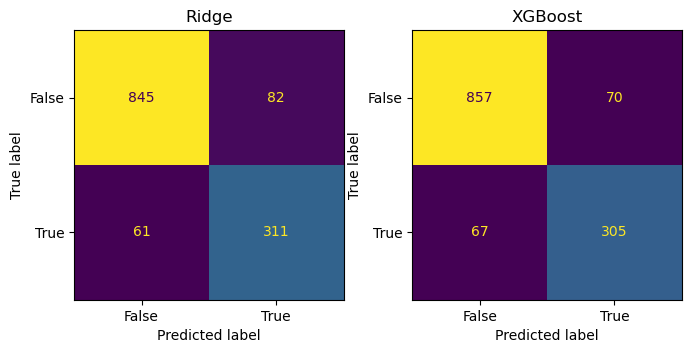

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, ConfusionMatrixDisplay

optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Дані + масштабування для Ridge
X_selected = X[top_features.index]
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

# 2. Ridge
ridge = Ridge(alpha=10.0).fit(X_train_scaled, y_train)
pred_ridge = ridge.predict(X_test_scaled)

# 3. Optuna для XGBoost
def objective(trial):
    model = XGBRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 500),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3),
        max_depth=trial.suggest_int("max_depth", 3, 8),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        random_state=42, n_jobs=-1)
    return -cross_val_score(model, X_train, y_train, cv=3, scoring="neg_mean_absolute_error").mean()

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)
print("Best parameters:", study.best_params)

# 4. XGBoost з найкращими параметрами
xgb = XGBRegressor(**study.best_params, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

# 5. Порівняння моделей
results = pd.DataFrame({
    'Модель': ['Ridge Regression', 'XGBoost (Optuna)'],
    'MAE (€)': [mean_absolute_error(y_test, p) for p in (pred_ridge, pred_xgb)],
    'RMSE (€)': [root_mean_squared_error(y_test, p) for p in (pred_ridge, pred_xgb)],
    'R2': [r2_score(y_test, p) for p in (pred_ridge, pred_xgb)]
})
pd.options.display.float_format = '{:,.2f}'.format
print(results)

#  Confusion matrix (дорого / дешево відносно середньої ціни)
m = y_test.mean()
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
ConfusionMatrixDisplay.from_predictions(y_test > m, pred_ridge > m, ax=ax[0], colorbar=False)
ax[0].set_title('Ridge')
ConfusionMatrixDisplay.from_predictions(y_test > m, pred_xgb > m, ax=ax[1], colorbar=False)
ax[1].set_title('XGBoost')
plt.show()


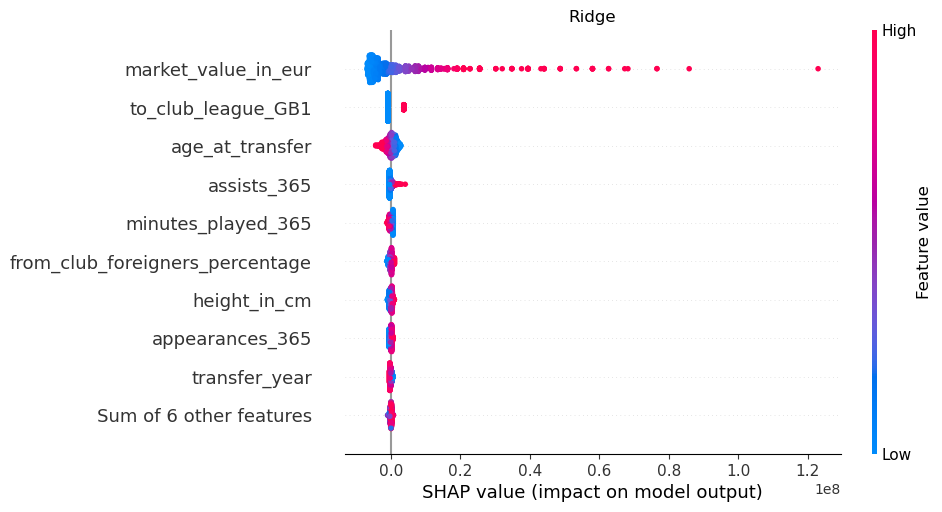

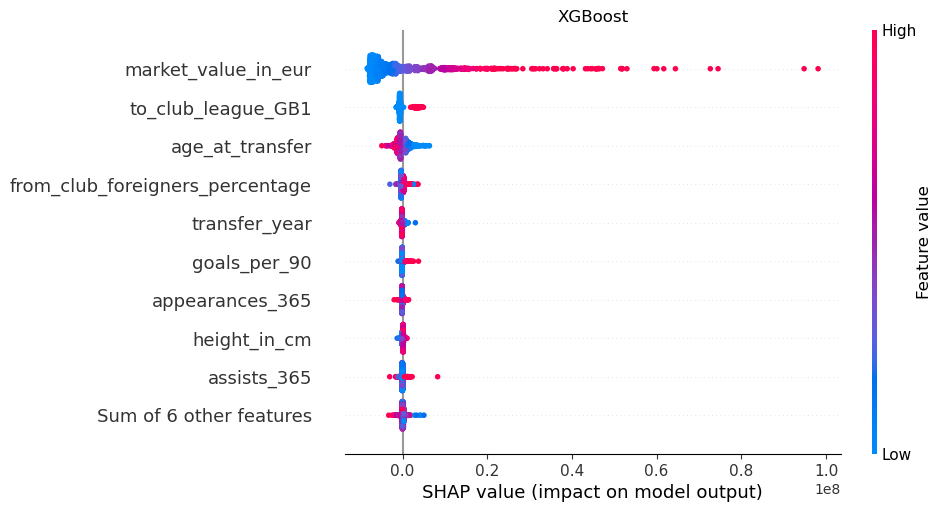

In [57]:
#  SHAP (з підписами)
shap_ridge = shap.LinearExplainer(ridge, X_train_scaled)(X_test_scaled)
shap.plots.beeswarm(shap_ridge, show=False)
plt.title('Ridge')
plt.show()

shap_xgb = shap.TreeExplainer(xgb)(X_test)
shap.plots.beeswarm(shap_xgb, show=False)
plt.title('XGBoost')
plt.show()
